   sepal_length  sepal_width  petal_length  petal_width        class
0           5.1          3.5           1.4          0.2  Iris-setosa
1           4.9          3.0           1.4          0.2  Iris-setosa
2           4.7          3.2           1.3          0.2  Iris-setosa
3           4.6          3.1           1.5          0.2  Iris-setosa
4           5.0          3.6           1.4          0.2  Iris-setosa


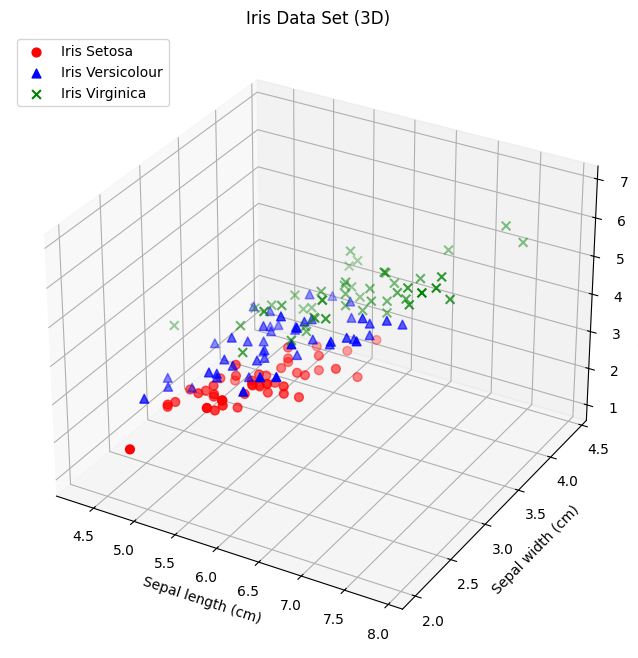

In [54]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits import mplot3d

url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data'
df = pd.read_csv(url, header=None, names=['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'class'])

print(df.head())

y = df.iloc[:, 4].values
x = df.iloc[:, 0:3].values

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
ax.set_title('Iris Data Set (3D)')
ax.set_xlabel("Sepal length (cm)")
ax.set_ylabel("Sepal width (cm)")
ax.set_zlabel("Petal length (cm)")

ax.scatter(x[:50, 0], x[:50, 1], x[:50, 2], color='red', marker='o', s=40, edgecolor='red', label="Iris Setosa")
ax.scatter(x[50:100, 0], x[50:100, 1], x[50:100, 2], color='blue', marker='^', s=40, edgecolor='blue', label="Iris Versicolour")
ax.scatter(x[100:150, 0], x[100:150, 1], x[100:150, 2], color='green', marker='x', s=40, label="Iris Virginica")

plt.legend(loc='upper left')
plt.show()

In [ ]:
import numpy as np

class Perceptron:
    def __init__(self, learning_rate=0.1):
        self.learning_rate = learning_rate
        self._b = 0.0
        self._w = None
        self._misclassified_samples = []

    def fit(self, x: np.array, y: np.array, n_iter=10):
        self._b = 0.0
        self._w = np.zeros(x.shape[1])
        self._misclassified_samples = []
        for _ in range(n_iter):
            errors = 0
            for xi, yi in zip(x, y):
                update = self.learning_rate * (yi - self.predict(xi))
                self._b += update
                self._w += update * xi
                errors += int(update != 0.0)
            self._misclassified_samples.append(errors)

    def f(self, x: np.array) -> float:
        return np.dot(x, self._w) + self._b

    def predict(self, x: np.array):
        return np.where(self.f(x) >= 0, 1, -1)

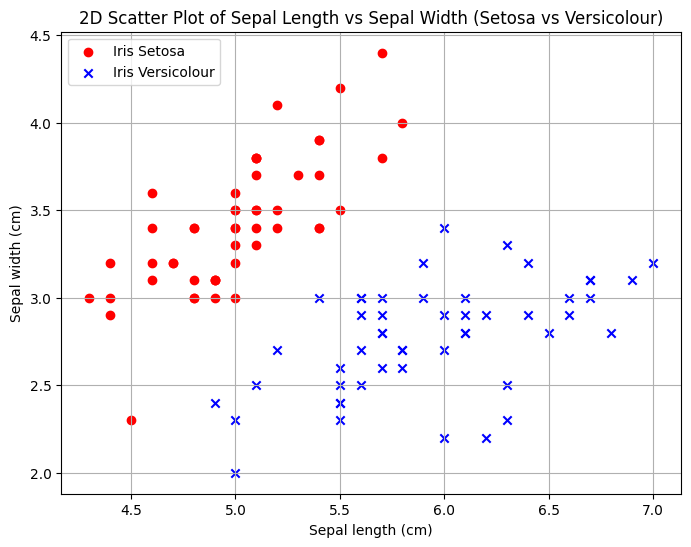

In [ ]:
import matplotlib.pyplot as plt

x_2d = df.iloc[0:100, 0:2].values
y_2d = df.iloc[0:100, 4].values

plt.figure(figsize=(8, 6))
plt.scatter(x_2d[:50, 0], x_2d[:50, 1], color='red', marker='o', label='Iris Setosa')
plt.scatter(x_2d[50:100, 0], x_2d[50:100, 1], color='blue', marker='x', label='Iris Versicolour')
plt.xlabel('Sepal length (cm)')
plt.ylabel('Sepal width (cm)')
plt.title('2D Scatter Plot of Sepal Length vs Sepal Width (Setosa vs Versicolour)')
plt.legend(loc='upper left')
plt.grid(True)
plt.show()

In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

x_perceptron = df.iloc[0:100, 0:2].values
y_perceptron_labels = df.iloc[0:100, 4].values

y_perceptron_transformed = np.where(y_perceptron_labels == 'Iris-setosa', 1, -1)

print("Original y labels (first 50):", y_perceptron_labels[:50])
print("Transformed y for Perceptron (first 50):", y_perceptron_transformed[:50])

x_perceptron[:, 0] = (x_perceptron[:, 0] - x_perceptron[:, 0].mean()) / x_perceptron[:, 0].std()
x_perceptron[:, 1] = (x_perceptron[:, 1] - x_perceptron[:, 1].mean()) / x_perceptron[:, 1].std()

print('\nStandardized X (first 5 rows):')
print(x_perceptron[:5])

X_train_p, X_test_p, y_train_p, y_test_p = train_test_split(
    x_perceptron,
    y_perceptron_transformed,
    test_size=0.25,
    random_state=0
)

print(f'\nShape of X_train: {X_train_p.shape}')
print(f'Shape of y_train: {y_train_p.shape}')
print(f'Shape of X_test: {X_test_p.shape}')
print(f'Shape of y_test: {y_test_p.shape}')

Original y labels (first 50): ['Iris-setosa' 'Iris-setosa' 'Iris-setosa' 'Iris-setosa' 'Iris-setosa'
 'Iris-setosa' 'Iris-setosa' 'Iris-setosa' 'Iris-setosa' 'Iris-setosa'
 'Iris-setosa' 'Iris-setosa' 'Iris-setosa' 'Iris-setosa' 'Iris-setosa'
 'Iris-setosa' 'Iris-setosa' 'Iris-setosa' 'Iris-setosa' 'Iris-setosa'
 'Iris-setosa' 'Iris-setosa' 'Iris-setosa' 'Iris-setosa' 'Iris-setosa'
 'Iris-setosa' 'Iris-setosa' 'Iris-setosa' 'Iris-setosa' 'Iris-setosa'
 'Iris-setosa' 'Iris-setosa' 'Iris-setosa' 'Iris-setosa' 'Iris-setosa'
 'Iris-setosa' 'Iris-setosa' 'Iris-setosa' 'Iris-setosa' 'Iris-setosa'
 'Iris-setosa' 'Iris-setosa' 'Iris-setosa' 'Iris-setosa' 'Iris-setosa'
 'Iris-setosa' 'Iris-setosa' 'Iris-setosa' 'Iris-setosa' 'Iris-setosa']
Transformed y for Perceptron (first 50): [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1]

Standardized X (first 5 rows):
[[-0.5810659   0.85713543]
 [-0.89430898 -0.19845007]
 [-1.20755205  0.22378413]
 [

In [ ]:
perceptron_classifier = Perceptron(learning_rate=0.01)
perceptron_classifier.fit(X_train_p, y_train_p)

y_pred_p = perceptron_classifier.predict(X_test_p)
accuracy = accuracy_score(y_test_p, y_pred_p)

print(f"Perceptron accuracy on the test set: {accuracy * 100:.2f}%")

Perceptron accuracy on the test set: 100.00%


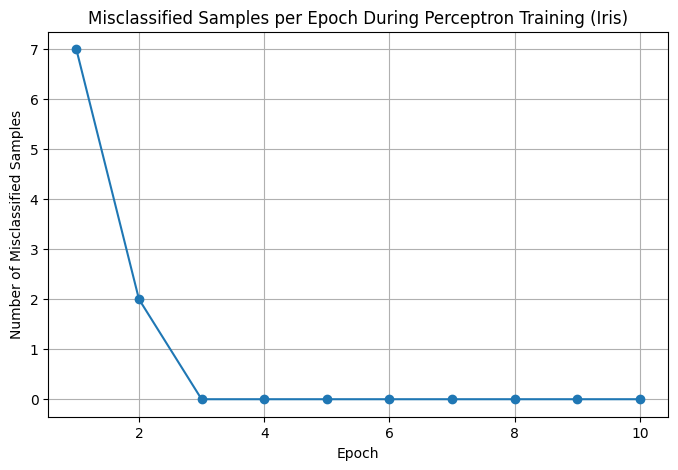

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(perceptron_classifier._misclassified_samples) + 1),
         perceptron_classifier._misclassified_samples,
         marker='o', linestyle='-')
plt.title('Misclassified Samples per Epoch During Perceptron Training (Iris)')
plt.xlabel('Epoch')
plt.ylabel('Number of Misclassified Samples')
plt.grid(True)
plt.show()